# MATH840 Final project — model family: ETS and exponential smoothing

ETS on every training length (3 days to 26 weeks), Holt-Winters, seasonal exponential smoothing, complex exponential smoothing (CES) and the Theta family; then three ways to adapt ETS to this series: one ETS per hour of the day, daily energy x the hourly profile, and a weather regression with ETS on its residual level.

Same data, same **20 rolling 48-hour windows** (one origin every midnight, 6–25 October), same scores as
`LUKIANETS_project_v2.ipynb`, judged on **day 2** (hours 25–48, the private leaderboard's hours). The last cell writes
`family_ets_bt.csv` and `family_ets_final.csv`; the main notebook merges them (Section 2.10) into one scoreboard, where the
combinations, the night rule and the final choice are made. Run it from top to bottom; the family notebooks are
independent of each other and can run at the same time. With `RESUME = True` (helpers cell) the models of an earlier
run are read back from the export and only new sections compute.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "LUKIANETS"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## The protocol (shared with every notebook)

In [5]:
import itertools
import os
import time
import logging
os.environ["NIXTLA_ID_AS_COL"] = "true"
for name in ("transformers", "root", "cmdstanpy", "prophet", "lightning", "lightning.pytorch", "gluonts",
             "nixtla.nixtla_client", "pytorch_lightning", "neuralforecast"):
    logging.getLogger(name).setLevel(logging.ERROR)

from IPython.display import display
from scipy import signal, stats
from scipy.special import boxcox
from coreforecast.scalers import boxcox_lambda
from statsmodels.tsa.seasonal import MSTL as MSTL_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsforecast.arima import ARIMASummary, ndiffs, nsdiffs
from statsforecast.models import ARIMA, AutoARIMA, AutoETS, AutoTheta, MSTL
try:
    from dotenv import load_dotenv
    load_dotenv()                  # .env next to the notebook holds NIXTLA_API_KEY: never paste the key here
except ImportError:
    pass

dates = data["ds"].reset_index(drop=True)
FREQ = "h"
DAY = 24
WINDOWS = 20                       # rolling 48-hour windows: the SAME on the Mac and in Colab (merged later)
STEP = 24                          # hours between window origins: one origin every midnight (6-25 October)
PART = "day2"                      # the hours a choice is judged on: "day2" (hours 25-48, the private part) or "all"
LAMBDA = 0.45                      # Box-Cox lambda (Guerrero on the last 12 weeks, Section 2.2)
FM_CONTEXT = 2048                  # hours of history a foundation model reads (default)

T0 = time.time()
def elapsed():
    print(f"[{(time.time() - T0) / 60:.1f} min since the start of Section 2]")

In [6]:
NAN = lambda h: np.full(h, np.nan)
FORECASTERS, MIXES, POST, FAMILY, FINAL = {}, {}, {}, {}, {}
bt = None
BASE_COLS = ("window", "step", "actual", "daylight", "benchmark", "benchmark lo", "benchmark hi")
PURGE = -(-H // STEP) - 1          # neighbours this close share hours with a window (1 for 48-hour windows a day apart)


def fwd(x, kind):
    x = np.asarray(x, float)
    if kind == "log":
        return np.log(x)
    if kind == "bc":
        return boxcox(x, LAMBDA)
    return x


def inv(z, kind):
    z = np.asarray(z, float)
    if kind == "log":
        return np.exp(z)
    if kind == "bc":
        return np.power(np.maximum(LAMBDA * z + 1, 1e-12), 1 / LAMBDA)
    return z


def weather_features(df: pd.DataFrame) -> pd.DataFrame:
    # the weather as regressors, plus the physical interactions trees and linear models cannot find alone
    df = df.reset_index(drop=True)
    out = df[["daylight", "cloud_cover", "temperature", "wind_speed", "humidity", "pressure", "air_density"]].astype(float).copy()
    out["sun"] = out["daylight"] * (1 - out["cloud_cover"])         # clear sky while the sun is up
    out["humid_day"] = out["daylight"] * out["humidity"]             # humidity matters while the sun is up
    out["wind3"] = out["wind_speed"] ** 3 / 100                      # wind power grows with the cube of the speed
    # Where the sun is, from the daylight column alone (no outside data): how long the day is, how far into its
    # daylight hours an hour lies, a clear-sky curve peaking at solar noon, and the season. 0/1 daylight cannot say
    # that late-October days are shorter and the sun lower, which is what the models missed in window 1.
    ds = pd.to_datetime(df["ds"])
    day = ds.dt.normalize().to_numpy()
    light = out["daylight"].to_numpy()
    length = pd.Series(light).groupby(day).transform("sum").to_numpy()
    order = pd.Series(light).groupby(day).cumsum().to_numpy()
    position = np.where(light == 1, (order - 0.5) / np.maximum(length, 1), 0.0)
    out["day_length"] = length
    out["sun_position"] = position
    out["clear_sky"] = np.where(light == 1, np.sin(np.pi * position), 0.0)
    out["doy_sin"] = np.sin(2 * np.pi * ds.dt.dayofyear.to_numpy() / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * ds.dt.dayofyear.to_numpy() / 365.25)
    return out


FEAT_DF = weather_features(pd.concat([data.drop(columns="y"), weather_fc], ignore_index=True))   # history, then the forecast
FEAT_COLS = list(FEAT_DF.columns)
FEAT = FEAT_DF.to_numpy()
ALL_DATES = pd.concat([dates, FUTURE], ignore_index=True)
COV_COLS = ["humidity", "wind_speed", "cloud_cover", "temperature", "daylight", "humid_day", "wind3"]   # the weather
SUN_COLS = ["day_length", "sun_position", "clear_sky", "doy_sin", "doy_cos"]                           # the sun


def cov(cols, start, stop):
    # covariate rows (len(cols), stop - start) for the absolute hours start .. stop-1 (the forecast after the history)
    return FEAT_DF[cols].to_numpy(float)[start:stop].T


def _clean(out, h) -> dict:
    get = lambda *keys: next((np.asarray(out[k], float).ravel()[:h] for k in keys if k in out), NAN(h))
    return {"mean": get("mean"), "lo": get("lo", "lo-95"), "hi": get("hi", "hi-95")}


def on_scale(fit_predict, transform="log"):
    # fit_predict(x, end, h) sees fwd(y[:end]); its forecasts come back on the original scale
    def forecast(end, h):
        out = _clean(fit_predict(fwd(y[:end], transform), end, h), h)
        out = {k: inv(v, transform) for k, v in out.items()}
        out["mean"], out["lo"] = np.maximum(out["mean"], 0), np.maximum(out["lo"], 0)
        return out
    return forecast


def sf(make, transform="log", context=1344, level=True):
    # a statsforecast model: make() builds a fresh one, fitted on the last `context` hours
    def fit_predict(x, end, h):
        x = x[-context:] if context else x
        return make().forecast(y=x, h=h, level=[95]) if level else make().forecast(y=x, h=h)
    return on_scale(fit_predict, transform)


FORECASTERS["benchmark"] = lambda end, h: dict(zip(("mean", "lo", "hi"), snaive(y[:end], h)))


def window_ends(windows=None):
    # where each window ends: window 1 ends with the history, the others STEP hours apart before it
    return [len(y) - (k - 1) * STEP for k in range(windows or WINDOWS, 0, -1)]


def backtest(forecasters: dict, windows=None) -> pd.DataFrame:
    # every forecaster on every window, each window forecast from the hours before it only
    windows = windows or WINDOWS
    ends = window_ends(windows)
    frames = []
    for k, e in zip(range(windows, 0, -1), ends):
        p, lo, hi = snaive(y[:e - H])
        frames.append(pd.DataFrame({"window": k, "step": np.arange(1, H + 1), "actual": y[e - H:e],
                                    "daylight": data["daylight"].to_numpy()[e - H:e],
                                    "benchmark": p, "benchmark lo": lo, "benchmark hi": hi}))
    frame = pd.concat(frames, ignore_index=True)
    bench_rmse = np.mean([rmse(g["actual"], g["benchmark"]) for _, g in frame.groupby("window")])
    seconds = {}
    for name, f in forecasters.items():
        start = time.time()
        try:
            parts = [_clean(f(e - H, H), H) for e in ends]
            if any(np.isnan(p["mean"]).any() for p in parts):
                raise ValueError("NaN in the forecast")
        except Exception as err:
            print(f"  ✗ {name}: {type(err).__name__}: {str(err)[:200]}")
            continue
        FORECASTERS[name] = f
        for key, col in (("mean", name), ("lo", f"{name} lo"), ("hi", f"{name} hi")):
            frame[col] = np.concatenate([p[key] for p in parts])
        seconds[name] = time.time() - start
        r = np.mean([rmse(g["actual"], g[name]) for _, g in frame.groupby("window")])
        print(f"  ✓ {name:<46s} RMSE {r:8.1f}  (skill {r / bench_rmse:.3f})   {seconds[name]:.1f}s", flush=True)
    frame.attrs["seconds"] = seconds
    return frame


def add(bt, new):
    out = bt.drop(columns=[c for c in new.columns if c in bt.columns and c not in BASE_COLS])
    out = pd.concat([out, new[[c for c in new.columns if c not in out.columns]]], axis=1)
    out.attrs["seconds"] = {**bt.attrs.get("seconds", {}), **new.attrs.get("seconds", {})}
    return out


def forecasts_in(bt) -> list[str]:
    return [c for c in bt.columns if c not in BASE_COLS and not c.endswith((" lo", " hi"))] + ["benchmark"]


def _part(frame, part=None):
    # the rows of the judged hours: day 2 = steps 25-48 (the private part), day 1 = steps 1-24, all = 1-48
    part = part or PART
    if part == "day2":
        return frame[frame["step"] > DAY]
    if part == "day1":
        return frame[frame["step"] <= DAY]
    return frame


def _per_window(rows, f, lo=None, hi=None):
    # RMSE, MAPE (and Winkler, coverage) of forecast f in each window of `rows`, as arrays (fast: no groupby)
    _, ix = np.unique(rows["window"].to_numpy(), return_inverse=True)
    n = np.bincount(ix)
    a, f = rows["actual"].to_numpy(float), np.asarray(f, float)
    out = [np.sqrt(np.bincount(ix, (a - f) ** 2) / n), np.bincount(ix, np.abs((a - f) / a)) / n * 100]
    if lo is not None:
        lo, hi = np.asarray(lo, float), np.asarray(hi, float)
        miss = np.clip(lo - a, 0, None) + np.clip(a - hi, 0, None)
        out += [np.bincount(ix, (hi - lo) + 40 * miss) / n, np.bincount(ix, ((a >= lo) & (a <= hi)).astype(float)) / n]
    return out


def window_table(columns=None, per_window=False, part=None) -> pd.DataFrame:
    # mean over the windows of the template's scores on the judged hours; skill = score / benchmark's;
    # won = windows with the lowest RMSE; beat bench = windows with a lower RMSE than the seasonal naive
    columns = list(dict.fromkeys((forecasts_in(bt) if columns is None else list(columns)) + ["benchmark"]))
    rows = _part(bt, part)
    ids = np.unique(rows["window"].to_numpy())
    stats_, per = {}, {}
    for c in columns:
        has = rows[f"{c} lo"].notna().all()
        r, m, *wc = _per_window(rows, rows[c], rows[f"{c} lo"] if has else None, rows[f"{c} hi"] if has else None)
        stats_[c] = {"RMSE": r.mean(), "MAPE": m.mean(), "Winkler": wc[0].mean() if has else np.nan,
                     "coverage": wc[1].mean() if has else np.nan}
        per[c] = pd.Series(r, index=ids)
    tab = pd.DataFrame(stats_).T
    b = tab.loc["benchmark"]
    tab["RMSE skill"], tab["MAPE skill"] = tab["RMSE"] / b["RMSE"], tab["MAPE"] / b["MAPE"]
    tab["point skill"] = (tab["RMSE skill"] + tab["MAPE skill"]) / 2
    tab["Winkler skill"] = tab["Winkler"] / b["Winkler"]
    w_rmse = pd.DataFrame(per)
    tab["won"] = [int((w_rmse.idxmin(axis=1) == c).sum()) for c in tab.index]
    tab["beat bench"] = [int((w_rmse[c] < w_rmse["benchmark"]).sum()) for c in tab.index]
    tab["seconds"] = [bt.attrs.get("seconds", {}).get(c, np.nan) for c in tab.index]
    tab = tab.sort_values("point skill")
    if per_window:
        return tab, (w_rmse.T / w_rmse["benchmark"]).loc[tab.index].round(2)
    return tab


def run(family: str, forecasters: dict, rerun=False) -> pd.DataFrame:
    global bt
    todo = {n: f for n, f in forecasters.items() if rerun or bt is None or n not in bt.columns}
    if todo:
        print(f"{family}: {len(todo)} forecaster(s) x {WINDOWS} windows")
        new = backtest(todo)
        bt = new if bt is None else add(bt, new)
    for n in forecasters:
        if n in bt.columns:
            FAMILY[n] = family
            if n in todo:
                FINAL.pop(n, None)            # re-run: its 48-hour forecast is computed again at the export
    return window_table([n for n in forecasters if n in bt.columns])


def best_of(family: str) -> str:
    names = [n for n, f in FAMILY.items() if f == family and n in bt.columns]
    return window_table(names).drop(index="benchmark")["point skill"].idxmin()


def combine(names, label, how="mean", interval_from=None):
    # the members' mean (or median); the interval: the members' mean interval, or -- interval_from -- that member's
    # own interval stretched to contain the combined point (for members without an interval of their own)
    names = [n for n in dict.fromkeys(names) if n in bt.columns]
    MIXES[label], FAMILY[label] = (names, how, interval_from), "combination"
    FINAL.pop(label, None)
    agg = (lambda cols, **kw: bt[cols].median(axis=1, **kw)) if how == "median" else (lambda cols, **kw: bt[cols].mean(axis=1, **kw))
    bt[label] = agg(names)
    if interval_from:
        bt[f"{label} lo"] = np.minimum(bt[f"{interval_from} lo"], bt[label])
        bt[f"{label} hi"] = np.maximum(bt[f"{interval_from} hi"], bt[label])
    else:
        bt[f"{label} lo"] = agg([f"{n} lo" for n in names], skipna=False)
        bt[f"{label} hi"] = agg([f"{n} hi" for n in names], skipna=False)


def others(w):
    # the windows that share no hour with window w: w and its PURGE neighbours on each side are left out
    return bt[(bt["window"] - w).abs() > PURGE]


def _radius(actual, point, daylight, recipe):
    # the 95% conformal radius from past errors: additive, or additive split day / night
    err = np.abs(np.asarray(actual, float) - np.asarray(point, float))
    if recipe == "conformal day/night":
        return {d: np.quantile(err[np.asarray(daylight) == d], 0.95) for d in (0, 1)}
    return np.quantile(err, 0.95)


def _bounds(point, daylight, r, recipe):
    point = np.asarray(point, float)
    rr = np.where(np.asarray(daylight) == 1, r[1], r[0]) if recipe == "conformal day/night" else r
    return np.maximum(point - rr, 0), point + rr


SCALES = np.round(np.arange(0.5, 1.501, 0.05), 2)


def _scaled(point, lo, hi, c):
    # the interval stretched (c > 1) or shrunk (c < 1) around the point forecast
    point, lo, hi = (np.asarray(v, float) for v in (point, lo, hi))
    return np.maximum(point - c * (point - lo), 0), point + c * (hi - point)


def _best_scale(rows, label):
    # the width factor with the lowest mean Winkler on `rows`
    p, lo, hi = rows[label], rows[f"{label} lo"], rows[f"{label} hi"]
    return min(SCALES, key=lambda c: _per_window(rows, p, *_scaled(p, lo, hi, c))[2].mean())


RECIPES = ["conformal", "conformal day/night"]


def interval_check(label: str, part=None) -> pd.DataFrame:
    # every recipe judged on windows it did not see: radius / width factor from the windows sharing no hour with it
    rows = []
    for w in sorted(bt["window"].unique()):
        g, o = _part(bt[bt["window"] == w], part), _part(others(w), part)
        recipes = {rec: _bounds(g[label], g["daylight"], _radius(o["actual"], o[label], o["daylight"], rec), rec) for rec in RECIPES}
        if g[f"{label} lo"].notna().all():
            recipes["own interval"] = (g[f"{label} lo"].to_numpy(), g[f"{label} hi"].to_numpy())
            recipes["own interval x c"] = _scaled(g[label], g[f"{label} lo"], g[f"{label} hi"], _best_scale(o, label))
        for rec, (lo, hi) in recipes.items():
            s = score(g["actual"], g[label], lo, hi)
            rows.append({"recipe": rec, "window": w, "Winkler": s["Winkler"], "coverage": s["coverage"],
                         "width": float(np.mean(np.asarray(hi) - np.asarray(lo)))})
    return pd.DataFrame(rows).groupby("recipe")[["Winkler", "coverage", "width"]].mean().sort_values("Winkler")


SHADE_FACTORS = np.round(np.arange(0.1, 1.001, 0.05), 2)
SHADE_LEVELS = (50, 100, 150, 200, 300)


def _shade(point, a, level):
    # the night rule: forecasts below `level` multiplied by a (MAPE punishes over-forecasting small values hardest)
    point = np.asarray(point, float)
    return np.where(point < level, a * point, point)


def _tune_post(frame, base, factors=SHADE_FACTORS):
    # the night rule (a, level) with the lowest RMSE skill + MAPE skill on the judged hours of `frame`
    # (base: a Series on frame's index); returns a, level and the RMSE skill + MAPE skill reached
    rows = _part(frame)
    b = base[rows.index].to_numpy()
    br, bm = _per_window(rows, rows["benchmark"])
    obj = lambda a, level: sum(v.mean() / ref.mean() for v, ref in zip(_per_window(rows, _shade(b, a, level)), (br, bm)))
    a, level = min(((a, L) for a in factors for L in SHADE_LEVELS), key=lambda p: obj(*p))
    return float(a), int(level), float(obj(a, level))


def postprocess(day_label, night_label=None, name=None, shade=True) -> str:
    # 1) the day model in daylight hours; at night the same model or its log-scale version, whichever scores
    #    better (night_label fixes it);
    # 2) the night rule: forecasts below `level` multiplied by a (shade=False: no rule).
    # The interval: the one of the model used at each hour, stretched to include the point; its width is judged in
    # interval_check like any model's. The night model, a and level are tuned on the windows sharing no hour with
    # the scored one (purged leave-one-window-out), so bt holds an honest score; the submission uses them tuned on
    # all windows.
    log = f"{day_label} log"
    nights = [night_label] if night_label else [day_label] + ([log] if log in bt.columns else [])
    name = name or f"{day_label} [{'post' if shade else 'hybrid'}]"
    factors = SHADE_FACTORS if shade else (1.0,)
    night = bt["daylight"].to_numpy() == 0
    pick = lambda n, s: pd.Series(np.where(night, bt[n + s], bt[day_label + s]), index=bt.index)

    def tune(frame):
        # [night model, a, level]: the night model whose tuned rule reaches the lowest RMSE skill + MAPE skill
        fits = {n: _tune_post(frame, pick(n, "")[frame.index], factors) for n in nights}
        n = min(fits, key=lambda k: fits[k][2])
        return [n, *fits[n][:2]]

    point, plo, phi = (pd.Series(np.nan, index=bt.index) for _ in range(3))
    chosen = []
    for w in sorted(bt["window"].unique()):
        n, a, level = tune(others(w))
        chosen.append(("log" if n == log else "same" if n == day_label else n, a, level))
        idx = bt.index[bt["window"] == w]
        point[idx] = _shade(pick(n, "")[idx], a, level)
        plo[idx] = np.minimum(pick(n, " lo")[idx], point[idx])
        phi[idx] = np.maximum(pick(n, " hi")[idx], point[idx])
    bt[name], bt[f"{name} lo"], bt[f"{name} hi"] = point, plo, phi
    n, a, level = tune(bt)
    POST[name], FAMILY[name] = {"day": day_label, "night": n, "a": a, "level": level}, "post-processed"
    FINAL.pop(name, None)
    print(f"{name}: night = {n}; submission rule a = {a}, level = {level}; held-out windows chose (night, a, level) "
          f"{pd.Series([str(x) for x in chosen]).value_counts().to_dict()}")
    return name


def from_all_of_y(label: str) -> dict:
    # every forecaster inside `label` once more on the WHOLE history (cached), averaged / post-processed as in bt
    if label not in FINAL:
        if label in MIXES:
            names, how, interval_from = MIXES[label]
            parts = {n: from_all_of_y(n) for n in names}
            agg = np.median if how == "median" else np.mean
            point = agg([p["mean"] for p in parts.values()], axis=0)
            if interval_from:
                lo, hi = np.minimum(parts[interval_from]["lo"], point), np.maximum(parts[interval_from]["hi"], point)
            else:
                lo, hi = (agg([p[k] for p in parts.values()], axis=0) for k in ("lo", "hi"))
            FINAL[label] = {"mean": point, "lo": lo, "hi": hi}
        elif label in POST:
            p = POST[label]
            d_, n_ = from_all_of_y(p["day"]), from_all_of_y(p["night"])
            night = weather_fc["daylight"].to_numpy()[:H] == 0
            base, lo, hi = (np.where(night, n_[k], d_[k]) for k in ("mean", "lo", "hi"))
            point = _shade(base, p["a"], p["level"])
            FINAL[label] = {"mean": point, "lo": np.minimum(lo, point), "hi": np.maximum(hi, point)}
        else:
            FINAL[label] = _clean(FORECASTERS[label](len(y), H), H)
    return FINAL[label]


def final_forecast(label: str, interval: str):
    # the 48 hours from the whole history; a conformal radius or width factor is fitted for each day of the horizon
    # separately (on all windows' day-1 errors for hours 1-24, on their day-2 errors for hours 25-48)
    fc = from_all_of_y(label)
    point = np.maximum(fc["mean"], 0)
    lo, hi = np.array(fc["lo"], float), np.array(fc["hi"], float)
    light = weather_fc["daylight"].to_numpy()[:H]
    for part, sl in (("day1", slice(0, DAY)), ("day2", slice(DAY, H))):
        rows = _part(bt, part)
        if interval == "own interval x c":
            lo[sl], hi[sl] = _scaled(point[sl], fc["lo"][sl], fc["hi"][sl], _best_scale(rows, label))
        elif interval in RECIPES:
            r = _radius(rows["actual"], rows[label], rows["daylight"], interval)
            lo[sl], hi[sl] = _bounds(point[sl], light[sl], r, interval)
        elif interval != "own interval":
            raise ValueError("interval: 'own interval', 'own interval x c' or one of RECIPES")
    if np.isnan(lo).any():
        raise ValueError(f"{label} has no interval of its own: use a conformal recipe")
    return point, np.minimum(np.maximum(lo, 0), point), np.maximum(hi, point)


def plot_validation(names, window=1, show=72):
    g = bt[bt["window"] == window]
    end = len(y) - (window - 1) * STEP
    x = dates.iloc[end - H:end]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(dates.iloc[end - H - show:end - H], y[end - H - show:end - H], color="grey", lw=0.8, label="history")
    ax.plot(x, g["actual"], color="black", lw=1.6, label="actual")
    ax.plot(x, g["benchmark"], color="grey", ls="--", lw=1.2, label="seasonal naive")
    ax.axvline(x.iloc[DAY - 1], color="grey", ls=":", lw=1)
    for n in names:
        ax.plot(x, g[n], lw=1.4, label=f"{n} (RMSE {rmse(g['actual'], g[n]):.1f})")
        if len(names) == 1 and g[f"{n} lo"].notna().all():
            ax.fill_between(x, g[f"{n} lo"], g[f"{n} hi"], alpha=0.2, label="95% interval")
    ax.set_title(f"window {window}" + (" (the template's validation window)" if window == 1 else "") + ": day 1 | day 2")
    ax.legend(loc="upper left", fontsize=8)
    plt.show()


RESULTS_DIR = "results"   # the exported model tables (<prefix>_bt.csv, <prefix>_final.csv) live here


def export(prefix: str):
    # the rolling-window table and each model's 48-hour forecast from the whole history, for merging elsewhere
    names = [n for n in forecasts_in(bt) if n != "benchmark" and n not in MIXES and n not in POST]
    Path(RESULTS_DIR).mkdir(exist_ok=True)
    bt[list(BASE_COLS) + [c for n in names for c in (n, f"{n} lo", f"{n} hi")]].to_csv(f"{RESULTS_DIR}/{prefix}_bt.csv", index=False)
    rows = []
    for n in names:
        try:
            fc = from_all_of_y(n)
        except Exception as err:
            print(f"  ✗ final forecast of {n}: {type(err).__name__}: {str(err)[:120]}")
            continue
        rows += [{"model": n, "family": FAMILY.get(n, "?"), "step": i + 1, "mean": fc["mean"][i], "lo": fc["lo"][i],
                  "hi": fc["hi"][i]} for i in range(H)]
    pd.DataFrame(rows).to_csv(f"{RESULTS_DIR}/{prefix}_final.csv", index=False)
    print(f"saved {RESULTS_DIR}/{prefix}_bt.csv ({len(names)} models) and {RESULTS_DIR}/{prefix}_final.csv")


def merge(prefix: str):
    # adds another notebook's exported models to bt, FAMILY and FINAL (the same windows are checked)
    global bt
    other = pd.read_csv(f"{RESULTS_DIR}/{prefix}_bt.csv")
    assert len(other) == len(bt) and (other["window"].to_numpy() == bt["window"].to_numpy()).all() \
        and np.allclose(other["actual"], bt["actual"]), "not the same windows: WINDOWS and STEP must match"
    new = [c for c in other.columns if c not in BASE_COLS]
    seconds = bt.attrs.get("seconds", {})
    bt = pd.concat([bt.drop(columns=[c for c in new if c in bt.columns]), other[new]], axis=1)
    bt.attrs["seconds"] = seconds
    fin = pd.read_csv(f"{RESULTS_DIR}/{prefix}_final.csv")
    for n, g in fin.groupby("model"):
        g = g.sort_values("step")
        FINAL[n] = {k: g[k].to_numpy(float) for k in ("mean", "lo", "hi")}
        FAMILY[n] = g["family"].iloc[0]
    print(f"merged {fin['model'].nunique()} models from {prefix}")

In [7]:
# Helpers used by the family notebooks
import os

RESUME = True       # <-- True: the models already in this notebook's export (an earlier run) are read back, only new
                    #     sections compute; False: everything from scratch
CONTEXTS = {"1w": 168, "2w": 336, "4w": 672, "8w": 1344, "12w": 2016, "26w": 4368}   # training lengths (hours)
LENGTH_ORDER = ["3d", "5d", "1w", "10d", "2w", "3w", "4w", "8w", "12w", "26w",
                "14d", "28d", "56d", "60d", "90d", "120d", "180d", "365d", "730d", "1095d"]


def resume(prefix):
    # RESUME: read back the models of this notebook's earlier export, so run() computes only the new ones
    global bt
    if RESUME and os.path.exists(f"{RESULTS_DIR}/{prefix}_bt.csv"):
        if bt is None:
            bt = pd.read_csv(f"{RESULTS_DIR}/{prefix}_bt.csv")[list(BASE_COLS)]
        merge(prefix)


def sf_any(make, transform="log", context=1344):
    # a statsforecast model with its 95% interval when it has one, the point forecast alone when it has not
    def fit_predict(x, end, h):
        x = x[-context:] if context else x
        try:
            return make().forecast(y=x, h=h, level=[95])
        except Exception:
            return make().forecast(y=x, h=h)
    return on_scale(fit_predict, transform)


def grid_view(table, value="point skill"):
    # "name, training length" rows -> a model x training-length table
    t = table.drop(index="benchmark").copy()
    t = t[[", " in n for n in t.index]]
    t["model"] = [n.rsplit(", ", 1)[0] for n in t.index]
    t["training"] = [n.rsplit(", ", 1)[1] for n in t.index]
    order = [c for c in LENGTH_ORDER if c in set(t["training"])]
    return t.pivot(index="model", columns="training", values=value)[order]


def show(table, title):
    print(title)
    display(table[["RMSE skill", "MAPE skill", "point skill", "Winkler skill", "coverage", "beat bench", "seconds"]].head(15).round(3))


# Regressors of the linear models: the weather + the sun (the set of the best DHR). Cloud-based interactions
# (clear-sky curve x (1 - cloud)) were tried and made linear models worse: cloud cover acts non-linearly here (EDA).
X_REG = ["humidity", "wind_speed", "cloud_cover", "temperature", "daylight", "humid_day", "wind3", "day_length", "clear_sky"]
X_DAILY = ["humid_day", "wind3", "temperature", "day_length"]          # daily means of these: a day's weather


def _try_forecast(model, y_, h, X=None, X_future=None):
    # the model's 95% interval when it has one, the point forecast alone when it has not
    kw = {} if X is None else {"X": X, "X_future": X_future}
    try:
        return model.forecast(y=y_, h=h, level=[95], **kw)
    except Exception:
        return model.forecast(y=y_, h=h, **kw)


def _varying(X, Xf):
    # drops the columns constant on the training rows (a regression cannot use them; e.g. daylight at 3 a.m.)
    keep = np.asarray(X).std(axis=0) > 1e-9
    return (X[:, keep], Xf[:, keep]) if keep.any() else (None, None)


def by_hour(make, transform="log", days=28, xcols=None):
    # one series per hour of the day: the last `days` values of each of the 24 hours form a daily series, forecast
    # 1 and 2 days ahead by make(); with xcols, that hour's weather as regressors (models that take X)
    def fit_predict(x, end, h):
        n = min(days, end // DAY)
        t = np.arange(end - n * DAY, end).reshape(n, DAY)                # rows: days; columns: the hours of the day
        steps = -(-h // DAY)
        tf = np.arange(end, end + steps * DAY).reshape(steps, DAY)
        F = FEAT_DF[xcols].to_numpy(float) if xcols else None
        out = {k: np.full(steps * DAY, np.nan) for k in ("mean", "lo", "hi")}
        for p in range(DAY):
            X, Xf = _varying(F[t[:, p]], F[tf[:, p]]) if xcols else (None, None)
            fc = _try_forecast(make(), np.asarray(x[t[:, p]], float), steps, X, Xf)
            for k, key in (("mean", "mean"), ("lo", "lo-95"), ("hi", "hi-95")):
                if key in fc:
                    out[k][p::DAY] = np.asarray(fc[key], float)[:steps]
        return {k: v[:h] for k, v in out.items()}
    return on_scale(fit_predict, transform)


def top_down(make, days=56, profile_days=7, transform="log", xcols=None):
    # the day's total (sum of its 24 hours) forecast by make() from the last `days` daily totals (on `transform`),
    # spread over the hours with the mean profile -- each hour's share of its day -- of the last `profile_days` days;
    # with xcols, the daily means of those columns as regressors (the forecast days' weather is known)
    def fit_predict(x, end, h):                                           # x: the original scale
        n = min(days, end // DAY)
        t = np.arange(end - n * DAY, end)
        block = np.asarray(x[t], float).reshape(n, DAY)
        recent = block[-profile_days:]
        share = (recent / recent.sum(axis=1, keepdims=True)).mean(axis=0)
        steps = -(-h // DAY)
        X = Xf = None
        if xcols:
            F = FEAT_DF[xcols].to_numpy(float)
            X = F[t].reshape(n, DAY, -1).mean(axis=1)
            Xf = F[np.arange(end, end + steps * DAY)].reshape(steps, DAY, -1).mean(axis=1)
            X, Xf = _varying(X, Xf)
        fc = _try_forecast(make(), fwd(block.sum(axis=1), transform), steps, X, Xf)
        return {k: np.concatenate([inv(np.asarray(fc[key], float)[d], transform) * share for d in range(steps)])[:h]
                for k, key in (("mean", "mean"), ("lo", "lo-95"), ("hi", "hi-95")) if key in fc}
    return on_scale(fit_predict, None)


def two_stage(make, xcols=X_REG, transform="log", context=2016, alpha=30.0):
    # regression with ETS (or other) errors in two stages: (1) ridge regression of the transformed series on the hour
    # of the day (24 dummies, not penalised) and the standardised weather, on the training window; (2) make() -- a
    # non-seasonal model -- on the DAILY MEANS of its residuals (what the weather does not explain: a level that moves),
    # forecast 1 and 2 days ahead and added to every hour of those days. (On the hourly residuals the last night's
    # residual was carried into tomorrow's midday and multiplied the peak.)
    def fit_predict(x, end, h):
        n = min(context, end) // DAY * DAY
        t, tf = np.arange(end - n, end), np.arange(end, end + h)
        hours = ALL_DATES.dt.hour.to_numpy()
        F = FEAT_DF[xcols].to_numpy(float)
        mu, sd = F[t].mean(axis=0), F[t].std(axis=0) + 1e-9
        design = lambda r: np.column_stack([(hours[r][:, None] == np.arange(DAY)).astype(float), (F[r] - mu) / sd])
        X, Xf = design(t), design(tf)
        z = np.asarray(x[t], float)
        beta = np.linalg.solve(X.T @ X + np.diag(np.r_[np.zeros(DAY), np.full(len(xcols), alpha)]), X.T @ z)
        resid = z - X @ beta
        steps = -(-h // DAY)
        fc = _try_forecast(make(), resid.reshape(-1, DAY).mean(axis=1), steps)
        reg = Xf @ beta
        spread = np.quantile(np.abs(resid - np.repeat(resid.reshape(-1, DAY).mean(axis=1), DAY)), 0.95)
        out = {"mean": reg + np.repeat(np.asarray(fc["mean"], float), DAY)[:h]}
        if "lo-95" in fc:   # the daily level's interval widened by the hours' spread around their day's mean
            out["lo"] = reg + np.repeat(np.asarray(fc["lo-95"], float), DAY)[:h] - spread
            out["hi"] = reg + np.repeat(np.asarray(fc["hi-95"], float), DAY)[:h] + spread
        return out
    return on_scale(fit_predict, transform)


def sf_x(make, xcols, transform="log", context=1344):
    # a statsforecast model that takes regressors (X, X_future): the weather of the training hours and of the horizon
    def fit_predict(x, end, h):
        t0 = max(0, end - context)
        F = FEAT_DF[xcols].to_numpy(float)
        return _try_forecast(make(), np.asarray(x[t0:], float), h, F[t0:end], F[end:end + h])
    return on_scale(fit_predict, transform)

In [8]:
resume("family_ets")      # reads back an earlier run when RESUME = True (see the cell above)

merged 135 models from family_ets


## 1. ETS on every training length (Lab 5)

Additive specifications on a transformed scale (log, Box-Cox 0.45), multiplicative ones on the original scale, and
AutoETS on all three — each fitted on 1, 2, 4, 8, 12 and 26 weeks before every window. A short window follows the
current level; a long one estimates the daily profile from more days but mixes in older levels.

In [9]:
def _ets_model(spec=None, m=DAY):
    if spec is None:
        return AutoETS(season_length=m)
    spec, damped = str(spec).strip().upper(), False
    if len(spec) == 4 and spec[2] == "D":
        spec, damped = spec[:2] + spec[3], True
    return AutoETS(season_length=m, model=spec, damped=damped if spec[1] != "N" else None)


ETS_SPECS = {                         # name: (letters, scale); letters None = AutoETS
    "ETS(A,N,A) log": ("ANA", "log"),  "ETS(A,A,A) log": ("AAA", "log"),  "ETS(A,Ad,A) log": ("AAdA", "log"),
    "ETS(A,N,A) bc":  ("ANA", "bc"),   "ETS(A,A,A) bc":  ("AAA", "bc"),   "ETS(A,Ad,A) bc":  ("AAdA", "bc"),
    "ETS(M,N,M)":     ("MNM", None),   "ETS(M,A,M)":     ("MAM", None),   "ETS(M,Ad,M)":     ("MAdM", None),
    "AutoETS log":    (None, "log"),   "AutoETS bc":     (None, "bc"),    "AutoETS":         (None, None),
}
ets_table = run("ETS", {f"{n}, {c}": sf(lambda spec=spec: _ets_model(spec), transform=kind, context=ctx)
                        for n, (spec, kind) in ETS_SPECS.items() for c, ctx in CONTEXTS.items()})
print("day-2 point skill by training length:")
display(grid_view(ets_table).round(3))
print("day-2 Winkler skill:")
display(grid_view(ets_table, "Winkler skill").round(3))
show(ets_table, "best ETS variants (day 2):")
elapsed()

day-2 point skill by training length:


training,1w,2w,4w,8w,12w,26w
model,,,,,,
AutoETS,1.968,2.220,2.197,2.288,1.565,0.870
AutoETS bc,1.825,1.716,1.406,1.406,0.826,0.863
AutoETS log,1.408,1.406,1.406,1.406,1.406,1.406
"ETS(A,A,A) bc",0.802,0.815,1.147,0.776,0.761,0.808
"ETS(A,A,A) log",0.791,0.735,3.003,0.863,0.851,0.916
"ETS(A,Ad,A) bc",0.773,0.747,0.744,0.756,0.779,0.793
"ETS(A,Ad,A) log",0.758,0.711,0.757,0.830,0.823,0.860
"ETS(A,N,A) bc",0.818,0.768,0.766,0.805,0.836,0.863
"ETS(A,N,A) log",0.768,0.824,0.864,1.114,1.217,1.300


day-2 Winkler skill:


training,1w,2w,4w,8w,12w,26w
model,,,,,,
AutoETS,32.137,6.570,3.234,2.595,1.324,0.946
AutoETS bc,3.600,2.701,1.420,1.401,0.977,0.962
AutoETS log,120.267,19.687,7.380,6.279,6.893,7.202
"ETS(A,A,A) bc",1.236,0.993,1.187,0.813,0.858,0.974
"ETS(A,A,A) log",2.068,1.742,4.303,1.102,1.203,1.126
"ETS(A,Ad,A) bc",0.733,0.577,0.683,0.789,0.846,0.934
"ETS(A,Ad,A) log",1.538,1.033,0.958,1.004,0.993,1.127
"ETS(A,N,A) bc",0.680,0.543,0.780,0.846,0.891,0.962
"ETS(A,N,A) log",1.279,0.990,1.263,1.426,1.777,1.899


best ETS variants (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"ETS(A,Ad,A) log, 2w",0.946,0.475,0.711,1.033,0.844,13,NaN
"ETS(A,A,A) log, 2w",1.057,0.413,0.735,1.742,0.775,12,NaN
"ETS(A,Ad,A) bc, 4w",0.844,0.645,0.744,0.683,0.829,14,NaN
"ETS(A,Ad,A) bc, 2w",0.886,0.607,0.747,0.577,0.858,14,NaN
"ETS(A,Ad,A) bc, 8w",0.863,0.649,0.756,0.789,0.777,14,NaN
"ETS(A,Ad,A) log, 4w",1.000,0.514,0.757,0.958,0.792,12,NaN
"ETS(A,Ad,A) log, 1w",1.099,0.416,0.758,1.538,0.821,10,NaN
"ETS(A,A,A) bc, 12w",0.920,0.602,0.761,0.858,0.756,12,NaN
"ETS(A,N,A) bc, 4w",0.899,0.633,0.766,0.780,0.819,12,NaN
"ETS(A,N,A) bc, 2w",0.848,0.687,0.768,0.543,0.862,15,NaN


[0.0 min since the start of Section 2]


## 2. The rest of the exponential-smoothing family

- **Holt-Winters** (additive on a transformed scale, multiplicative on the original);
- **seasonal exponential smoothing** (level per hour of the day, optimised smoothing);
- **CES** — complex exponential smoothing (Svetunkov), a non-linear cousin of ETS;
- the **Theta** family (the M3 winner and its optimised / dynamic versions) — Theta is SES with drift on a
  deseasonalised series.

In [10]:
from statsforecast.models import (AutoCES, DynamicOptimizedTheta, DynamicTheta, HoltWinters, OptimizedTheta,
                                  SeasonalExponentialSmoothingOptimized, Theta)

RELATIVES, THETAS = {}, {}
for c in ("2w", "4w", "8w"):
    for kind in ("log", "bc", None):
        tag = kind or "raw"
        RELATIVES[f"Seasonal ES {tag}, {c}"] = sf_any(lambda: SeasonalExponentialSmoothingOptimized(season_length=DAY), kind, CONTEXTS[c])
        RELATIVES[f"CES {tag}, {c}"] = sf_any(lambda: AutoCES(season_length=DAY), kind, CONTEXTS[c])
        RELATIVES[f"Holt-Winters {'multiplicative' if kind is None else 'additive'} {tag}, {c}"] = sf_any(
            lambda e="M" if kind is None else "A": HoltWinters(season_length=DAY, error_type=e), kind, CONTEXTS[c])
        for nm, cls in (("Theta", Theta), ("Optimized Theta", OptimizedTheta), ("Dynamic Theta", DynamicTheta),
                        ("DOTM", DynamicOptimizedTheta)):
            THETAS[f"{nm} {tag}, {c}"] = sf_any(lambda cls=cls: cls(season_length=DAY), kind, CONTEXTS[c])
show(run("exp. smoothing (other)", RELATIVES), "Holt-Winters, seasonal ES, CES (day 2):")
show(run("Theta", THETAS), "the Theta family (day 2):")
elapsed()

Holt-Winters, seasonal ES, CES (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"CES raw, 4w",0.991,0.144,0.567,1.910,0.531,8,NaN
"CES raw, 8w",0.961,0.201,0.581,1.830,0.529,9,NaN
"Seasonal ES log, 2w",0.881,0.349,0.615,NaN,NaN,13,NaN
"CES raw, 2w",1.171,0.092,0.631,2.425,0.477,6,NaN
"Seasonal ES log, 4w",0.880,0.383,0.632,NaN,NaN,12,NaN
"Seasonal ES log, 8w",0.887,0.390,0.638,NaN,NaN,14,NaN
"Seasonal ES bc, 2w",0.880,0.424,0.652,NaN,NaN,13,NaN
"Seasonal ES bc, 4w",0.885,0.506,0.696,NaN,NaN,11,NaN
"Seasonal ES bc, 8w",0.894,0.517,0.706,NaN,NaN,13,NaN
"Holt-Winters additive log, 2w",0.952,0.475,0.714,1.029,0.840,13,NaN


the Theta family (day 2):

,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
benchmark,1.000,1.000,1.000,1.000,0.817,0,NaN
"DOTM raw, 4w",1.735,0.517,1.126,0.973,0.885,6,NaN
"Optimized Theta raw, 4w",1.741,0.517,1.129,0.975,0.885,6,NaN
"Theta raw, 4w",1.747,0.513,1.130,0.964,0.885,4,NaN
"Dynamic Theta raw, 4w",1.753,0.513,1.133,0.961,0.885,4,NaN
"DOTM raw, 2w",1.766,0.502,1.134,0.956,0.883,5,NaN
"Theta raw, 2w",1.769,0.503,1.136,0.950,0.881,6,NaN
"Optimized Theta raw, 2w",1.767,0.508,1.137,0.957,0.883,6,NaN
"Theta bc, 4w",1.762,0.516,1.139,4.134,0.883,7,NaN
"DOTM raw, 8w",1.765,0.516,1.141,1.086,0.877,6,NaN


[0.0 min since the start of Section 2]


## 3. How much history? Shorter training lengths, and two fixes

Section 1 is U-shaped in the training length: 1 week is too little to estimate the 24 seasonal states, 8+ weeks mix
in older levels (the level moved fast in 2026). This section fills in the curve around the optimum — **3, 5 and 10
days, 3 weeks** — for the specifications that did best.

Two fixes found in sections 1–2:
- **AutoETS chose no season.** By AICc it picked ETS(A,N,N) — a flat line — on the log and Box-Cox scales (skill
  ~2.3). `model="ZZA"` keeps the error and trend automatic but forces an additive season.
- **Theta's deseasonalising** is multiplicative by default: on a log scale (values near or below 0) and with night
  values near 0 it breaks. `decomposition_type="additive"` on log / Box-Cox.

ETS: 32 forecaster(s) x 20 windows


  ✓ ETS(A,N,A) log, 3d                             RMSE    290.4  (skill 0.929)   0.1s


  ✓ ETS(A,N,A) log, 5d                             RMSE    354.6  (skill 1.134)   0.2s


  ✓ ETS(A,N,A) log, 10d                            RMSE    359.0  (skill 1.148)   0.3s


  ✓ ETS(A,N,A) log, 3w                             RMSE    401.9  (skill 1.285)   0.5s


  ✓ ETS(A,Ad,A) log, 3d                            RMSE    689.0  (skill 2.203)   0.2s


... (25 outputs left out)

  ✓ AutoETS seasonal bc, 4w                        RMSE    283.6  (skill 0.907)   8.0s


  ✓ AutoETS seasonal bc, 8w                        RMSE    308.3  (skill 0.986)   18.2s


ETS: day-2 RMSE skill by training length (sections 1 and 3):


training,3d,5d,1w,10d,2w,3w,4w,8w,12w,26w
model,,,,,,,,,,
"ETS(A,N,A) log",0.887,1.107,1.014,1.095,1.084,1.193,1.172,1.560,1.853,2.001
"ETS(A,N,A) bc",0.962,0.950,0.969,0.890,0.848,0.928,0.899,0.972,1.050,1.110
"ETS(A,Ad,A) bc",1.167,1.001,0.982,0.960,0.886,0.862,0.844,0.863,0.921,0.953
"ETS(M,N,M)",1.667,1.285,1.162,1.117,0.935,0.939,0.942,0.930,0.889,1.017
"ETS(M,Ad,M)",2.191,1.238,1.046,0.972,0.925,0.940,0.943,0.918,0.894,0.928
"ETS(A,Ad,A) log",2.359,1.316,1.099,1.006,0.946,0.970,1.000,1.088,1.110,1.172
AutoETS,NaN,NaN,2.378,NaN,2.350,NaN,2.338,2.413,1.434,1.071
AutoETS bc,NaN,NaN,2.606,NaN,2.531,NaN,2.300,2.300,1.150,1.110
AutoETS log,NaN,NaN,2.302,NaN,2.300,NaN,2.300,2.300,2.300,2.300


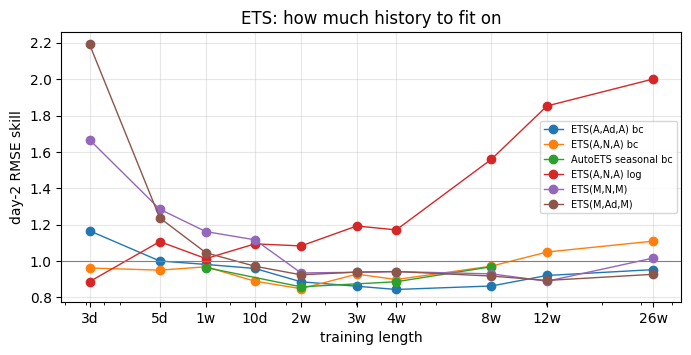

exp. smoothing (other): 16 forecaster(s) x 20 windows
  ✓ Seasonal ES log, 5d                            RMSE    279.1  (skill 0.892)   0.0s


  ✓ Holt-Winters additive log, 5d                  RMSE    442.9  (skill 1.416)   0.7s


  ✓ Seasonal ES log, 1w                            RMSE    278.7  (skill 0.891)   0.0s


  ✓ Holt-Winters additive log, 1w                  RMSE    355.4  (skill 1.136)   0.8s


  ✓ Seasonal ES log, 10d                           RMSE    278.0  (skill 0.889)   0.0s


  ✓ Holt-Winters additive log, 10d                 RMSE    341.9  (skill 1.093)   1.2s


... (24 outputs left out)

  ✓ DOTM additive bc, 4w                           RMSE    390.8  (skill 1.250)   0.5s


Theta deseasonalised additively (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"Theta additive bc, 4w",1.193,0.506,0.849,1.038e+01,1.000,10,0.349
"DOTM additive bc, 4w",1.197,0.510,0.854,1.038e+01,1.000,10,0.471
"Optimized Theta additive bc, 4w",1.200,0.509,0.854,1.037e+01,1.000,9,0.525
"Theta additive bc, 2w",1.255,0.495,0.875,1.130e+01,1.000,8,0.161
"DOTM additive bc, 2w",1.275,0.494,0.884,1.124e+01,1.000,7,0.216
"Optimized Theta additive bc, 2w",1.278,0.497,0.887,1.127e+01,1.000,7,0.207
benchmark,1.000,1.000,1.000,1.000e+00,0.817,0,NaN
"Theta additive log, 4w",1.819,0.518,1.168,3.643e+04,1.000,6,0.327
"Optimized Theta additive log, 4w",1.839,0.523,1.181,3.643e+04,1.000,6,0.448
"DOTM additive log, 4w",1.839,0.524,1.182,3.698e+04,1.000,6,0.561


[1.3 min since the start of Section 2]


In [11]:
SHORT = {"3d": 72, "5d": 120, "10d": 240, "3w": 504}
SHORT_SPECS = ["ETS(A,N,A) log", "ETS(A,Ad,A) log", "ETS(A,N,A) bc", "ETS(A,Ad,A) bc", "ETS(M,N,M)", "ETS(M,Ad,M)"]
SHORT_ETS = {f"{n}, {c}": sf(lambda spec=ETS_SPECS[n][0]: _ets_model(spec), transform=ETS_SPECS[n][1], context=ctx)
             for n in SHORT_SPECS for c, ctx in SHORT.items()}
for kind in ("log", "bc"):
    for c in ("1w", "2w", "4w", "8w"):
        SHORT_ETS[f"AutoETS seasonal {kind}, {c}"] = sf(lambda: AutoETS(season_length=DAY, model="ZZA"), transform=kind,
                                                        context=CONTEXTS[c])
run("ETS", SHORT_ETS)
curve = grid_view(window_table([n for n, f in FAMILY.items() if f == "ETS"]), "RMSE skill")
print("ETS: day-2 RMSE skill by training length (sections 1 and 3):")
display(curve.round(3).sort_values(curve.columns.tolist()[0]))
HOURS = {**CONTEXTS, **SHORT}
fig, ax = plt.subplots(figsize=(8, 3.5))
for m in curve.min(axis=1).sort_values().index[:6]:
    row = curve.loc[m].dropna()
    ax.plot([HOURS[c] for c in row.index], row.to_numpy(), marker="o", lw=1, label=m)
ax.set_xscale("log")
ax.set_xticks([HOURS[c] for c in curve.columns])
ax.set_xticklabels(curve.columns)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xlabel("training length")
ax.set_ylabel("day-2 RMSE skill")
ax.set_title("ETS: how much history to fit on")
ax.legend(fontsize=7)
plt.show()

MORE_ES = {}
for kind in ("log", "bc"):
    for c, ctx in (("5d", 120), ("1w", 168), ("10d", 240), ("3w", 504)):
        MORE_ES[f"Seasonal ES {kind}, {c}"] = sf_any(lambda: SeasonalExponentialSmoothingOptimized(season_length=DAY), kind, ctx)
        MORE_ES[f"Holt-Winters additive {kind}, {c}"] = sf_any(lambda: HoltWinters(season_length=DAY, error_type="A"), kind, ctx)
show(run("exp. smoothing (other)", MORE_ES), "seasonal ES and Holt-Winters on shorter lengths (day 2):")
THETA_FIX = {f"{nm} additive {kind}, {c}": sf_any(lambda cls=cls: cls(season_length=DAY, decomposition_type="additive"),
                                                  kind, CONTEXTS[c])
             for nm, cls in (("Theta", Theta), ("Optimized Theta", OptimizedTheta), ("DOTM", DynamicOptimizedTheta))
             for kind in ("log", "bc") for c in ("2w", "4w")}
show(run("Theta", THETA_FIX), "Theta deseasonalised additively (day 2):")
elapsed()

## 4. One ETS per hour of the day

Electricity forecasters often split an hourly series into **24 daily series**, one per hour of the day: the 13:00
series only ever sees 13:00 values, so the daily profile needs no seasonal states at all, and each hour gets its own
level and smoothing — the midday hours lose more in late October than the night hours. Each series is forecast 1 and 2
days ahead with a non-seasonal ETS fitted on its last 14, 28 or 56 days.

In [12]:
PER_HOUR = {}
for days in (14, 28, 56):
    for kind in ("log", "bc"):
        PER_HOUR[f"per-hour ETS(A,N,N) {kind}, {days}d"] = by_hour(lambda: _ets_model("ANN", m=1), kind, days)
        PER_HOUR[f"per-hour ETS(A,Ad,N) {kind}, {days}d"] = by_hour(lambda: _ets_model("AAdN", m=1), kind, days)
        PER_HOUR[f"per-hour AutoETS {kind}, {days}d"] = by_hour(lambda: AutoETS(season_length=1), kind, days)
per_hour_table = run("ETS per hour", PER_HOUR)
display(grid_view(per_hour_table).round(3))
show(per_hour_table, "one ETS per hour of the day (day 2):")
elapsed()

ETS per hour: 18 forecaster(s) x 20 windows


  ✓ per-hour ETS(A,N,N) log, 14d                   RMSE    306.3  (skill 0.979)   0.4s


  ✓ per-hour ETS(A,Ad,N) log, 14d                  RMSE    311.4  (skill 0.996)   0.9s


  ✓ per-hour AutoETS log, 14d                      RMSE    308.5  (skill 0.986)   1.7s


  ✓ per-hour ETS(A,N,N) bc, 14d                    RMSE    306.8  (skill 0.981)   0.4s


  ✓ per-hour ETS(A,Ad,N) bc, 14d                   RMSE    308.5  (skill 0.986)   0.7s


... (13 outputs left out)

training,14d,28d,56d
model,,,
per-hour AutoETS bc,0.733,0.779,0.760
per-hour AutoETS log,0.677,0.706,0.697
"per-hour ETS(A,Ad,N) bc",0.709,0.705,0.707
"per-hour ETS(A,Ad,N) log",0.666,0.642,0.649
"per-hour ETS(A,N,N) bc",0.729,0.765,0.757
"per-hour ETS(A,N,N) log",0.676,0.686,0.683


one ETS per hour of the day (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"per-hour ETS(A,Ad,N) log, 28d",0.951,0.333,0.642,0.603,0.848,8,0.942
"per-hour ETS(A,Ad,N) log, 56d",0.882,0.416,0.649,0.624,0.835,15,1.182
"per-hour ETS(A,Ad,N) log, 14d",0.995,0.338,0.666,0.811,0.894,12,0.867
"per-hour ETS(A,N,N) log, 14d",0.948,0.404,0.676,0.738,0.881,10,0.384
"per-hour AutoETS log, 14d",0.953,0.400,0.677,0.738,0.877,10,1.667
"per-hour ETS(A,N,N) log, 56d",0.904,0.461,0.683,0.637,0.833,13,0.446
"per-hour ETS(A,N,N) log, 28d",0.945,0.427,0.686,0.627,0.846,8,0.369
"per-hour AutoETS log, 56d",0.904,0.489,0.697,0.645,0.829,13,2.871
"per-hour ETS(A,Ad,N) bc, 28d",0.976,0.435,0.705,0.477,0.923,8,0.845
"per-hour AutoETS log, 28d",0.960,0.453,0.706,0.663,0.821,9,2.204


[1.7 min since the start of Section 2]


## 5. Daily energy × the hourly profile (top-down)

Forecast the **day's total** — a smooth daily series, no daily cycle left — with ETS, then spread it over the hours with
the mean profile of the last 7 days (each hour's share of its day). The daily total carries the level (the autumn
decline); the profile carries the shape.

In [13]:
TOPDOWN = {}
for days in (28, 56, 112):
    for kind in ("log", "bc"):
        TOPDOWN[f"daily AutoETS x profile {kind}, {days}d"] = top_down(lambda: AutoETS(season_length=1), days, 7, kind)
        TOPDOWN[f"daily ETS(A,Ad,N) x profile {kind}, {days}d"] = top_down(lambda: _ets_model("AAdN", m=1), days, 7, kind)
td_table = run("ETS top-down", TOPDOWN)
display(grid_view(td_table).round(3))
show(td_table, "daily ETS x hourly profile (day 2):")
elapsed()

ETS top-down: 12 forecaster(s) x 20 windows
  ✓ daily AutoETS x profile log, 28d               RMSE    307.2  (skill 0.982)   0.1s


  ✓ daily ETS(A,Ad,N) x profile log, 28d           RMSE    305.8  (skill 0.978)   0.1s


  ✓ daily AutoETS x profile bc, 28d                RMSE    307.3  (skill 0.983)   0.1s


  ✓ daily ETS(A,Ad,N) x profile bc, 28d            RMSE    265.9  (skill 0.850)   0.0s


  ✓ daily AutoETS x profile log, 56d               RMSE    279.3  (skill 0.893)   0.1s


  ✓ daily ETS(A,Ad,N) x profile log, 56d           RMSE    278.7  (skill 0.891)   0.1s


... (6 outputs left out)

training,28d,56d
model,,
daily AutoETS x profile bc,0.742,0.758
daily AutoETS x profile log,0.731,0.755
"daily ETS(A,Ad,N) x profile bc",0.640,0.757
"daily ETS(A,Ad,N) x profile log",0.773,0.754


daily ETS x hourly profile (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"daily ETS(A,Ad,N) x profile bc, 28d",0.831,0.449,0.640,0.844,0.725,14,0.022
"daily AutoETS x profile log, 28d",0.955,0.507,0.731,0.985,0.598,11,0.094
"daily ETS(A,Ad,N) x profile log, 112d",0.902,0.575,0.738,1.065,0.575,13,0.062
"daily AutoETS x profile log, 112d",0.902,0.575,0.738,1.086,0.567,13,0.181
"daily AutoETS x profile bc, 28d",0.966,0.518,0.742,0.943,0.619,12,0.116
"daily AutoETS x profile bc, 112d",0.907,0.577,0.742,1.077,0.556,13,0.185
"daily ETS(A,Ad,N) x profile bc, 112d",0.908,0.580,0.744,1.016,0.608,13,0.069
"daily ETS(A,Ad,N) x profile log, 56d",0.912,0.596,0.754,0.986,0.635,14,0.063
"daily AutoETS x profile log, 56d",0.914,0.597,0.755,0.993,0.629,15,0.117
"daily ETS(A,Ad,N) x profile bc, 56d",0.915,0.598,0.757,0.936,0.679,14,0.034


[1.7 min since the start of Section 2]


## 6. ETS with the weather: a regression first, ETS on what is left

ETS cannot read the weather — the main reason it trails the regressions and the foundation models (day 2 depends on
tomorrow's clouds). Two stages, the ETS counterpart of regression with ARIMA errors:

1. ridge regression of the log series on the **hour of the day** (24 dummies) and the **weather + sun** (the regressors
   of the best DHR: humidity, wind, wind³, cloud, temperature, daylight, humidity in daylight, day length, clear-sky
   curve), fitted on the training window;
2. a **non-seasonal ETS on the daily means of the residuals** — what the weather does not explain, e.g. a level that
   is moving — forecast 1 and 2 days ahead and added to every hour of those days.

Forecast = the regression on the horizon's weather + the residual level's ETS forecast. "Regression alone" (residual
forecast 0) shows what the ETS stage adds; `alpha` is the ridge penalty. (A first version ran ETS on the *hourly*
residuals: it carried the last night's residual into tomorrow's midday and multiplied the peak — skill > 1.)

In [14]:
class ZeroResidual:
    # the residual model of "regression alone": the residuals are forecast as 0
    def forecast(self, y, h, **kw):
        return {"mean": np.zeros(h)}


ETSX = {}
for c in ("4w", "8w", "12w", "26w"):
    for alpha in (30, 100):
        ETSX[f"weather regression a={alpha} + ETS(A,N,N) log, {c}"] = two_stage(lambda: _ets_model("ANN", m=1), X_REG, "log", CONTEXTS[c], alpha)
        ETSX[f"weather regression a={alpha} + ETS(A,Ad,N) log, {c}"] = two_stage(lambda: _ets_model("AAdN", m=1), X_REG, "log", CONTEXTS[c], alpha)
        ETSX[f"weather regression a={alpha} alone log, {c}"] = two_stage(ZeroResidual, X_REG, "log", CONTEXTS[c], alpha)
    ETSX[f"weather regression a=30 + ETS(A,N,N) bc, {c}"] = two_stage(lambda: _ets_model("ANN", m=1), X_REG, "bc", CONTEXTS[c], 30)
etsx_table = run("ETS + weather", ETSX)
display(grid_view(etsx_table).round(3))
show(etsx_table, "regression on the weather + ETS on the residuals (day 2):")
elapsed()

ETS + weather: 28 forecaster(s) x 20 windows


  ✓ weather regression a=30 + ETS(A,N,N) log, 4w   RMSE    294.5  (skill 0.942)   15.0s


  ✓ weather regression a=30 + ETS(A,Ad,N) log, 4w  RMSE    328.2  (skill 1.049)   14.6s


  ✓ weather regression a=30 alone log, 4w          RMSE    294.4  (skill 0.941)   14.4s


  ✓ weather regression a=100 + ETS(A,N,N) log, 4w  RMSE    287.6  (skill 0.920)   14.7s


  ✓ weather regression a=100 + ETS(A,Ad,N) log, 4w RMSE    331.4  (skill 1.060)   15.5s


... (23 outputs left out)

training,4w,8w,12w,26w
model,,,,
"weather regression a=100 + ETS(A,Ad,N) log",0.629,0.606,0.582,0.605
"weather regression a=100 + ETS(A,N,N) log",0.570,0.554,0.533,0.609
weather regression a=100 alone log,0.574,0.577,0.559,0.569
"weather regression a=30 + ETS(A,Ad,N) log",0.618,0.605,0.556,0.604
"weather regression a=30 + ETS(A,N,N) bc",0.557,0.576,0.648,0.617
"weather regression a=30 + ETS(A,N,N) log",0.577,0.572,0.528,0.590
weather regression a=30 alone log,0.577,0.582,0.561,0.569


regression on the weather + ETS on the residuals (day 2):


,RMSE skill,MAPE skill,point skill,Winkler skill,coverage,beat bench,seconds
"weather regression a=30 + ETS(A,N,N) log, 12w",0.724,0.332,0.528,1.008,0.881,17,29.266
"weather regression a=100 + ETS(A,N,N) log, 12w",0.729,0.337,0.533,1.028,0.879,17,39.022
"weather regression a=100 + ETS(A,N,N) log, 8w",0.811,0.296,0.554,1.001,0.892,16,28.721
"weather regression a=30 + ETS(A,Ad,N) log, 12w",0.775,0.338,0.556,1.026,0.873,16,35.595
"weather regression a=30 + ETS(A,N,N) bc, 4w",0.751,0.363,0.557,0.453,0.985,14,24.931
"weather regression a=100 alone log, 12w",0.775,0.342,0.559,NaN,NaN,15,42.067
"weather regression a=30 alone log, 12w",0.788,0.335,0.561,NaN,NaN,15,36.508
"weather regression a=30 alone log, 26w",0.797,0.340,0.569,NaN,NaN,13,39.146
"weather regression a=100 alone log, 26w",0.796,0.342,0.569,NaN,NaN,13,43.027
"weather regression a=100 + ETS(A,N,N) log, 4w",0.827,0.312,0.570,1.041,0.900,14,14.747


[16.2 min since the start of Section 2]


## Summary and export

In [15]:
summary, per_window = window_table(per_window=True)
print("day 2 (the private hours):")
display(summary.head(30))
print("all 48 hours:")
display(window_table(part="all").head(15))
print("day-2 RMSE relative to the seasonal naive, window by window (window 1 = the most recent):")
display(per_window.head(15))
for f in dict.fromkeys(FAMILY.values()):
    if f != "simple":
        print(f"best {f}: {best_of(f)}")
export("family_ets")
elapsed()

day 2 (the private hours):


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"weather regression a=30 + ETS(A,N,N) log, 12w",243.217,378.943,2760.870,0.881,0.724,0.332,0.528,1.008,0,17,29.266
"weather regression a=100 + ETS(A,N,N) log, 12w",244.640,385.159,2817.421,0.879,0.729,0.337,0.533,1.028,0,17,39.022
"weather regression a=100 + ETS(A,N,N) log, 8w",272.424,338.164,2742.437,0.892,0.811,0.296,0.554,1.001,0,16,28.721
"weather regression a=30 + ETS(A,Ad,N) log, 12w",260.135,385.373,2812.094,0.873,0.775,0.338,0.556,1.026,1,16,35.595
"weather regression a=30 + ETS(A,N,N) bc, 4w",252.182,413.808,1241.056,0.985,0.751,0.363,0.557,0.453,0,14,24.931
"weather regression a=100 alone log, 12w",260.190,390.871,NaN,NaN,0.775,0.342,0.559,NaN,0,15,42.067
"weather regression a=30 alone log, 12w",264.503,381.794,NaN,NaN,0.788,0.335,0.561,NaN,0,15,36.508
"CES raw, 4w",332.737,164.015,5234.818,0.531,0.991,0.144,0.567,1.910,0,8,NaN
"weather regression a=30 alone log, 26w",267.725,388.047,NaN,NaN,0.797,0.340,0.569,NaN,0,13,39.146
"weather regression a=100 alone log, 26w",267.138,390.236,NaN,NaN,0.796,0.342,0.569,NaN,0,13,43.027


all 48 hours:


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"CES raw, 4w",322.794,118.663,4383.310,0.609,1.032,0.157,0.595,1.604,0,7,NaN
"CES raw, 8w",318.031,162.678,4398.772,0.595,1.017,0.216,0.616,1.610,3,9,NaN
"weather regression a=30 + ETS(A,N,N) log, 12w",254.743,362.291,2744.160,0.887,0.815,0.481,0.648,1.004,0,14,29.266
"CES raw, 2w",372.639,90.902,5398.345,0.573,1.191,0.121,0.656,1.976,1,6,NaN
"weather regression a=100 + ETS(A,N,N) log, 12w",259.652,364.916,2763.176,0.886,0.830,0.484,0.657,1.011,0,16,39.022
"weather regression a=30 + ETS(A,N,N) bc, 4w",251.818,393.835,1238.751,0.985,0.805,0.523,0.664,0.453,0,14,24.931
"weather regression a=100 + ETS(A,N,N) log, 8w",285.388,324.571,2691.139,0.899,0.913,0.431,0.672,0.985,0,13,28.721
"weather regression a=30 + ETS(A,N,N) bc, 8w",243.190,430.141,1276.796,0.980,0.778,0.571,0.674,0.467,2,16,35.771
"weather regression a=30 + ETS(A,Ad,N) log, 12w",274.317,361.667,2774.312,0.879,0.877,0.480,0.679,1.015,1,13,35.595
"weather regression a=30 alone log, 4w",294.434,318.355,NaN,NaN,0.941,0.423,0.682,NaN,0,11,14.385


day-2 RMSE relative to the seasonal naive, window by window (window 1 = the most recent):


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
"weather regression a=30 + ETS(A,N,N) log, 12w",0.71,0.57,0.46,0.85,0.77,0.68,0.81,0.55,0.66,0.85,0.69,0.72,0.82,0.57,1.18,1.10,0.88,0.27,0.73,1.67
"weather regression a=100 + ETS(A,N,N) log, 12w",0.93,0.72,0.45,0.84,0.76,0.63,0.77,0.54,0.65,0.85,0.71,0.71,0.84,0.45,1.07,1.45,0.91,0.27,0.75,1.61
"weather regression a=100 + ETS(A,N,N) log, 8w",0.93,0.62,0.39,0.83,0.69,0.83,0.99,0.68,0.79,0.98,0.91,0.83,1.10,0.44,1.03,1.63,0.96,0.26,0.70,1.43
"weather regression a=30 + ETS(A,Ad,N) log, 12w",0.69,0.55,0.49,0.84,0.75,0.71,0.88,0.53,0.62,1.40,0.64,0.72,0.82,0.46,1.16,1.38,0.91,0.29,0.73,1.68
"weather regression a=30 + ETS(A,N,N) bc, 4w",1.36,1.53,0.81,0.74,1.02,0.34,0.60,0.46,0.53,0.79,0.66,0.78,0.97,0.75,0.85,1.22,1.08,0.31,0.88,1.53
"weather regression a=100 alone log, 12w",1.47,1.32,0.45,0.84,0.76,0.63,0.77,0.54,0.65,0.85,0.71,0.84,0.99,0.58,1.07,1.16,0.89,0.32,0.63,2.03
"weather regression a=30 alone log, 12w",1.69,1.50,0.46,0.85,0.77,0.68,0.81,0.55,0.66,0.85,0.69,0.85,0.98,0.57,1.18,1.10,0.88,0.27,0.65,2.07
"CES raw, 4w",1.17,2.15,1.36,1.38,0.81,0.53,0.26,0.25,0.57,1.28,1.40,0.66,0.86,1.21,1.76,1.41,1.69,0.40,1.01,2.84
"weather regression a=30 alone log, 26w",1.40,1.59,0.48,0.91,0.84,0.64,0.80,0.54,0.63,0.82,0.71,0.84,1.00,0.59,1.12,1.24,1.04,0.39,0.80,1.60
"weather regression a=100 alone log, 26w",1.31,1.50,0.49,0.90,0.84,0.62,0.78,0.53,0.64,0.83,0.72,0.85,1.03,0.61,1.09,1.31,1.07,0.37,0.81,1.56


best ETS: ETS(A,N,A) log, 3d


best exp. smoothing (other): CES raw, 4w
best Theta: Theta additive bc, 4w
best ETS per hour: per-hour ETS(A,Ad,N) log, 28d


best ETS top-down: daily ETS(A,Ad,N) x profile bc, 28d
best ETS + weather: weather regression a=30 + ETS(A,N,N) log, 12w


saved family_ets_bt.csv (253 models) and family_ets_final.csv
[17.2 min since the start of Section 2]
